# 트리 기반 회귀 (Decision Tree Regression)

## 가. 트리 기반 회귀의 개념 및 동작 원리
### 1. **연속형 숫자 값 예측** : 분류 문제와 달리 클래스 레이블이 아닌 연속적인 숫자 값(`Value`)을 예측
### 2. **리프 노드의 평균값 사용** : 새로운 데이터가 트리를 타고 내려가 도달한 최종 리프 노드(Leaf Node)에 속한 학습용 데이터들의 **평균(Mean)**을 해당 영역의 최종 예측값으로 사용
### 3. **분할 기준 (Splitting Criterion)** : 평균제곱오차(MSE, Mean Squared Error)를 최소화하는 피처(Feature)와 임계값(Threshold)을 탐색하여 데이터를 두 개의 서브셋으로 나눔

In [1]:
# 1. 필요한 라이브러리 임포트
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error

In [2]:
# 2. 데이터 불러오기
df1 = pd.read_csv('./실습데이터/house_price.csv')

In [3]:
# 데이터 상위 5행 확인
display(df1.head())

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [4]:
# 데이터 크기 및 결측치 확인
print("데이터 형태 (Shape):", df1.shape)
print("결측치 개수:\n", df1.isnull().sum())

데이터 형태 (Shape): (506, 14)
결측치 개수:
 crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
medv       0
dtype: int64


In [5]:
# 3. 독립변수(X)와 종속변수(y) 분리
# medv: 집값 (예측 대상 타겟)
X1 = df1.drop(columns=['medv'])
y1 = df1['medv']

In [6]:
# 4. 학습용 데이터와 평가용 데이터 분할 (8:2 비율)
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.25, random_state=0
)

print(f"학습용 데이터 크기: {X1_train.shape}, 평가용 데이터 크기: {X1_test.shape}")

학습용 데이터 크기: (379, 13), 평가용 데이터 크기: (127, 13)


In [7]:
# 5. 결정 트리 회귀 모델 생성 및 학습
dt_reg1 = DecisionTreeRegressor(random_state=0)
dt_reg1.fit(X1_train, y1_train)
print(dt_reg1.get_depth())

18


In [8]:
# 6. 평가용 데이터를 이용한 예측
pred_test1 = dt_reg1.predict(X1_test)

In [9]:
# 7. 모델 성능 평가 (RMSE)
rmse_dt1 = root_mean_squared_error(y1_test, pred_test1)
print(f"Decision Tree Regressor RMSE: {rmse_dt1:.4f}")

Decision Tree Regressor RMSE: 5.4067


In [10]:
# max_depth를 제한하여 과대적합 방지 및 일반화 성능 개선
# max_depth = 6일때 최대성능 (RMSE: 4.9152)
dt_reg1_tuned = DecisionTreeRegressor(max_depth=6, random_state=0)
dt_reg1_tuned.fit(X1_train, y1_train)
print(dt_reg1_tuned.get_depth())

6


In [11]:
pred_test_tuned1 = dt_reg1_tuned.predict(X1_test)
rmse_tuned1 = root_mean_squared_error(y1_test, pred_test_tuned1)

print(f"규제 적용 후 (max_depth=6) RMSE: {rmse_tuned1:.4f}")

규제 적용 후 (max_depth=6) RMSE: 4.9152


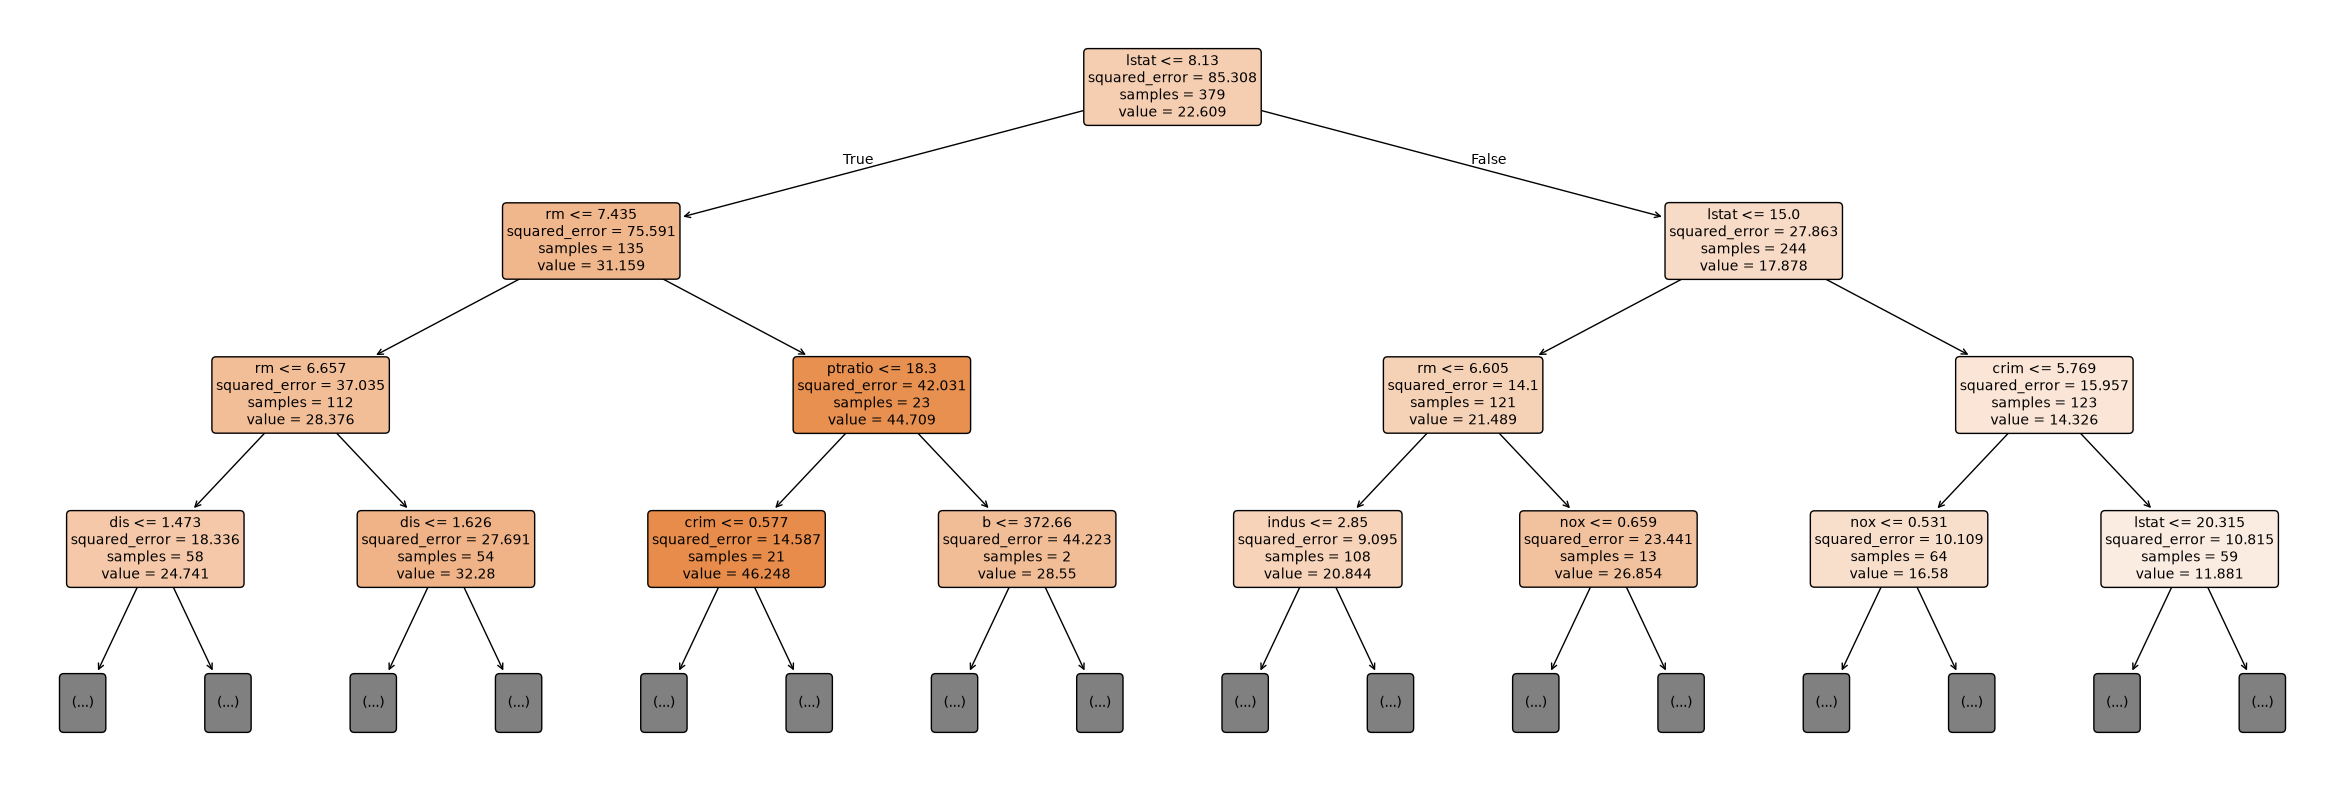

In [12]:
import matplotlib.pyplot as plt
from sklearn import tree

plt.figure(figsize=(30, 10))

# 2. matplotlib을 이용해 의사결정 트리 그리기
tree.plot_tree(
    dt_reg1,
    feature_names=X1.columns,
    filled=True,
    rounded=True,  # 노드 테두리를 둥글게 만들어 줍니다 (선택사항)
    fontsize=10,  # 글씨 크기 조절
    max_depth=3
)

# 3. 화면에 출력
plt.show()

## 나. 결정 트리의 한계와 불안정성 (Instability)

### 1. **축 수직 분할(Axis-aligned Boundaries)의 한계**
   * 결정 트리는 공간을 항상 '축에 수직'인 형태로만 분할
   * 실제 데이터의 정답 경계선이 완만한 대각선이나 곡선 형태라면, 단일 트리는 이를 표현하기 위해 수많은 '계단 모양'으로 조각내야 하므로 매끄럽지 못한 경계면으로 인해 예측 오차가 발생
### 2. **높은 분산(High Variance) 및 민감성**
   * 훈련 데이터의 아주 미세한 변화(샘플의 추가 또는 삭제)에도 트리 전체 구조가 완전히 재구성될 수 있습니다.
### 3. **해결 방안**
   - 단일 결정 트리의 불안정성과 과대적합 문제를 극복하기 위해 여러 개의 트리를 결합하는 **앙상블(Ensemble: 랜덤 포레스트, 부스팅 등)** 기법을 활용